# Categorical decision trees from scratch

**ID3 · Entropy · Information gain · Recursive prediction**

This notebook explains how a decision tree learns a categorical rule. The
core functions live in `tree.py`. The main file, `run_experiment.py`, generates
data, learns the models, evaluates them, and saves the results. `plotting.py`
only draws figures. No scikit-learn estimator is used to train this tree.

**Before running:** install the environment from the repository README, select
its `.venv` kernel, and use **Restart Kernel and Run All Cells**. No data
download is required. Save the notebook afterward to retain its outputs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from decision_trees.tree import build_tree, entropy, information_gain, predict_one, tree_to_text
from decision_trees.run_experiment import run_experiment, save_results
from decision_trees.plotting import plot_tree, plot_confusion_matrix

%matplotlib inline
pd.set_option('display.precision', 4)

## 1. A small, fully generated example

The generator enumerates 144 distinct combinations of six categorical features:
weather, wind, temperature, company, day type, and time of day. The labels
come from this **invented teaching rule**, not measurements:

```text
cloudy                              -> walk
sunny AND calm wind                 -> walk
otherwise                           -> indoor
```

Only weather and wind affect the label. The other four features let us see
whether information gain finds relevant attributes. This is an algorithm
demonstration, not a model of real preferences or advice about activities.

The shared experiment uses seed 42 and a 75/25 split: 108 training rows and
36 test rows. We display a few generated training rows below. These are
synthetic examples created by the repository, not an external dataset.

In [2]:
result = run_experiment()
train, test = result['train'], result['test']
assert set(train.index).isdisjoint(test.index)

display(pd.DataFrame({
    'split': ['training', 'testing'],
    'rows': [len(train), len(test)],
    'walk': [(train.label == 'walk').sum(), (test.label == 'walk').sum()],
    'indoor': [(train.label == 'indoor').sum(), (test.label == 'indoor').sum()],
}))
display(train.head(6))

,split,rows,walk,indoor
0,training,108,56,52
1,testing,36,16,20


,weather,wind,temperature,company,day_type,time_of_day,label
20,sunny,calm,warm,group,weekday,morning,walk
56,cloudy,calm,mild,solo,weekday,morning,walk
3,sunny,calm,cool,solo,weekend,evening,walk
127,rainy,strong,cool,group,weekend,evening,indoor
78,cloudy,strong,cool,group,weekend,morning,walk
101,rainy,calm,cool,group,weekday,evening,indoor


Every feature combination occurs only once, so the two splits cannot contain
identical feature rows. All gains, node majorities, and branches are learned
from the training rows. Test labels are used only for evaluation. The three
model settings used below are fixed in advance.

## 2. Why split on one feature rather than another?

Label entropy measures class uncertainty:

$$H(D)=-\sum_k p_k\log_2 p_k.$$

A pure binary-class node has entropy 0; an evenly balanced node has entropy
1 bit. For a categorical feature $a$, information gain is

$$IG(D,a)=H(D)-\sum_{v\in\mathrm{values}(a)}\frac{|D_v|}{|D|}H(D_v).$$

The weights matter: a large subset contributes more than a small one. ID3
chooses the feature that most reduces this weighted uncertainty. The
calculation below shows all gains at the root and the subsets for weather.

In [3]:
display(result['gains'].sort_values('information_gain_bits', ascending=False))

subsets = []
for category, subset in train.groupby('weather', sort=False):
    subsets.append({
        'weather': category,
        'rows': len(subset),
        'entropy_bits': entropy(subset.label),
        'weighted_entropy_bits': len(subset) / len(train) * entropy(subset.label),
    })
display(pd.DataFrame(subsets))
display(Markdown(
    f"Training entropy is **{entropy(train.label):.4f} bits**. "
    f"Splitting on weather removes **{information_gain(train, 'weather'):.4f} bits**. "
    "Weather has the greatest gain, so it becomes the root feature."
))

,feature,information_gain_bits
0,weather,6.9366e-01
1,wind,5.7571e-02
3,company,2.2979e-04
5,time_of_day,1.9633e-04
2,temperature,1.2418e-04
4,day_type,1.3611e-06


,weather,rows,entropy_bits,weighted_entropy_bits
0,sunny,33,0.9993,0.3054
1,cloudy,39,-0.0000,-0.0000
2,rainy,36,-0.0000,-0.0000


Training entropy is **0.9990 bits**. Splitting on weather removes **0.6937 bits**. Weather has the greatest gain, so it becomes the root feature.

## 3. Build the tree recursively

`build_tree(train)` chooses a feature, groups rows by its category values, and
repeats the same operation inside each group. A used feature is removed from
that branch's candidates. Recursion stops when labels are pure, no features
remain, or an optional depth limit is reached.

A node is an ordinary dictionary:

```python
{'feature': ..., 'children': ..., 'prediction': ..., 'samples': ...}
```

`prediction` is that node's training-majority label. It is used at leaves and
as a fallback for unseen categories. `feature=None` identifies a leaf.
The training procedure never reads the label-generation rule itself.

There are two target classes, but weather has three branches: this is a
**multiway categorical tree**, not necessarily a binary tree.

```text
split weather (n=108, fallback=walk)
  [sunny] split wind (n=33, fallback=walk)
    [calm] predict walk (n=17)
    [strong] predict indoor (n=16)
  [cloudy] predict walk (n=39)
  [rainy] predict indoor (n=36)
```

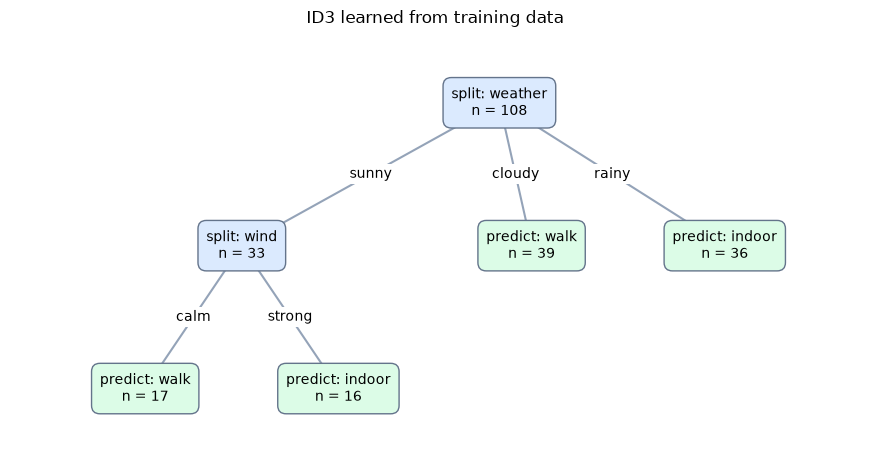

In [4]:
tree = build_tree(train)
assert tree == result['tree']
display(Markdown('```text\n' + tree_to_text(tree) + '\n```'))
plot_tree(tree)
plt.show()

## 4. Follow one prediction

For a sunny observation with strong wind, follow `weather = sunny` and then
`wind = strong`. The leaf predicts `indoor`. Prediction only reads the
features encountered along this path; it does not use the actual label.

In [5]:
sample = {'weather': 'sunny', 'wind': 'strong'}
display(pd.DataFrame([{**sample, 'prediction': predict_one(tree, sample)}]))

,weather,wind,prediction
0,sunny,strong,indoor


## 5. Evaluate on the same held-out rows

Compare full ID3 with a **one-split tree** (`max_depth=1`) and the
**training-majority baseline** (`max_depth=0`). The root is at depth 0, so
depth 0 allows no splits. Depth 1 can use weather but cannot make the next
wind split for sunny observations.

Accuracy is the number of correct predictions divided by the number of rows
in that split. The confusion matrix is for full ID3; rows are actual labels
and columns are predictions. The sample prediction table contains generated
test row IDs and labels, not an external dataset.

,method,train_accuracy,test_accuracy
0,ID3,1.0000,1.0000
1,One-split tree,0.8519,0.7778
2,Majority baseline,0.5185,0.4444


,row_id,actual,ID3,One-split tree,Majority baseline
0,15,walk,walk,walk,walk
1,48,walk,walk,walk,walk
2,60,walk,walk,walk,walk
3,109,indoor,indoor,indoor,walk
4,9,walk,walk,walk,walk
5,62,walk,walk,walk,walk


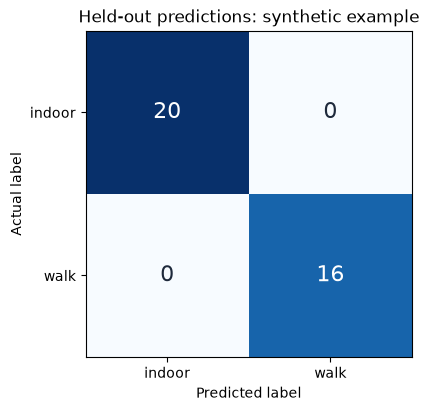

In [6]:
display(result['metrics'].round(4))
display(result['predictions'].head(6))
plot_confusion_matrix(result['predictions'])
plt.show()

### Interpreting the scores

The test set contains combinations not used for fitting. Nevertheless, all
labels follow a simple, noise-free rule using familiar categories. A perfect
score here shows that the tree recovered this rule; it does not establish
real-world accuracy or performance on unfamiliar distributions.

In [7]:
scores = result['metrics'].set_index('method')
correct = (result['predictions']['ID3'] == result['predictions']['actual']).sum()
display(Markdown(
    f"Full ID3 correctly predicts **{correct}/{len(test)}** test rows. "
    f"The one-split tree scores **{scores.loc['One-split tree', 'test_accuracy']:.2%}**, "
    f"and the training-majority baseline scores "
    f"**{scores.loc['Majority baseline', 'test_accuracy']:.2%}**. "
    "The one-split model underfits the sunny/wind interaction. "
    "This example does not show that increasing depth always improves generalization."
))

Full ID3 correctly predicts **36/36** test rows. The one-split tree scores **77.78%**, and the training-majority baseline scores **44.44%**. The one-split model underfits the sunny/wind interaction. This example does not show that increasing depth always improves generalization.

## 6. What happens with a new category?

The generator never produces snowy weather or breezy wind. When a branch
does not exist, prediction returns the majority label of the **current
node**. Both examples below return `walk` in this fitted tree. This is a
default based on training counts, not a learned judgment about the new value.
Missing feature values are a separate issue: the DataFrame training and
prediction functions reject them rather than imputing them.

In [8]:
new_examples = [
    {'weather': 'snowy', 'wind': 'strong'},
    {'weather': 'sunny', 'wind': 'breezy'},
]
display(pd.DataFrame([
    {**sample, 'prediction': predict_one(tree, sample)} for sample in new_examples
]))

,weather,wind,prediction
0,snowy,strong,walk
1,sunny,breezy,walk


## 7. Scope and limitations

- This implementation treats each observed value as a category. It does not
  search for numeric thresholds, prune the fitted tree, or impute missing data.
- Equal gains use feature column order; majority ties use the first label in
  the training subset. Removing a feature at each level guarantees termination.
- Zero gain does not force stopping: an interaction such as XOR can require
  a first split whose immediate gain is zero. The tests cover this case.
- Greedy information gain can favor high-cardinality features, and deep trees
  can overfit noisy data. This clean finite example does not assess those risks.
- A future real-data comparison should use validation or cross-validation on
  training data to choose depth, then evaluate once on an untouched test set.

The ID3 implementation here makes multiway category splits. scikit-learn's
decision trees use CART-style binary splits, so they are not a drop-in check
for identical ID3 tree structure.

## 8. Save the same results as the main program

The following cell uses the shared exporter. It writes three CSV files
(metrics, root gains, and synthetic test predictions), `tree.txt`, two PNG
figures, and `metadata.json` under `decision_trees/results/`. Running it again
replaces these seven files. The full generated feature table is not exported.

To reproduce these files without Jupyter, run this from the repository root:

```bash
python -m decision_trees.run_experiment
```

In [9]:
save_results(result)
display(Markdown('Saved all seven result files under `decision_trees/results/`.'))

Saved all seven result files under `decision_trees/results/`.

## References

- J. R. Quinlan, [Induction of decision trees](https://doi.org/10.1007/BF00116251),
  *Machine Learning* 1, 81–106 (1986).
- [scikit-learn: tree algorithms](https://scikit-learn.org/stable/modules/tree.html#tree-algorithms-id3-c4-5-c5-0-and-cart).

All example rows and labels in this notebook are generated by this
repository's `make_demo_data()` function.